### Load & Explore Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/day.csv")

df["dteday"] = pd.to_datetime(df["dteday"])

df = df.sort_values("dteday").reset_index(drop=True)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Info:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDate Range:")
print(df["dteday"].min(), "to", df["dteday"].max())

Dataset Shape: (731, 16)

First 5 Rows:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), 

### Time Series Visualization

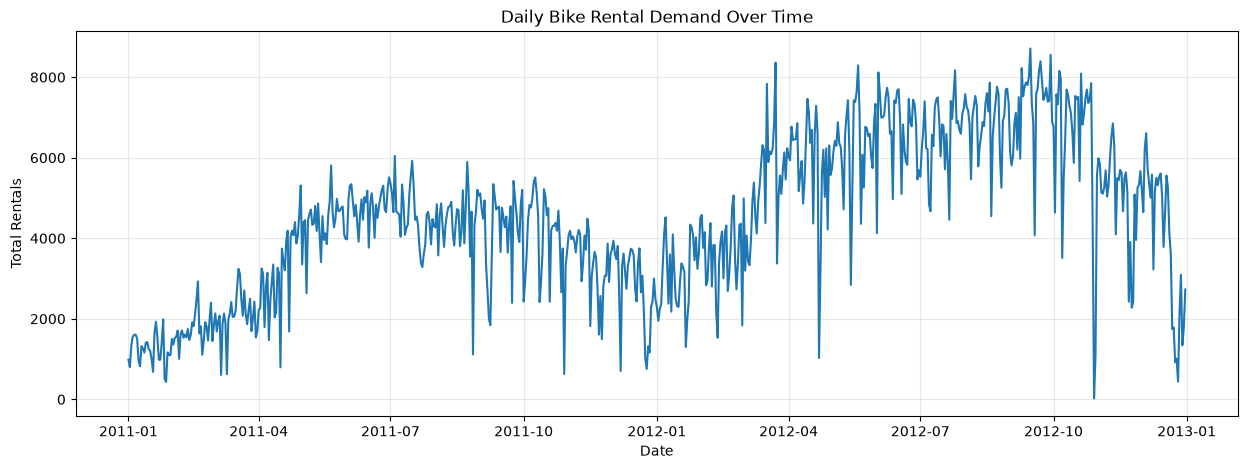

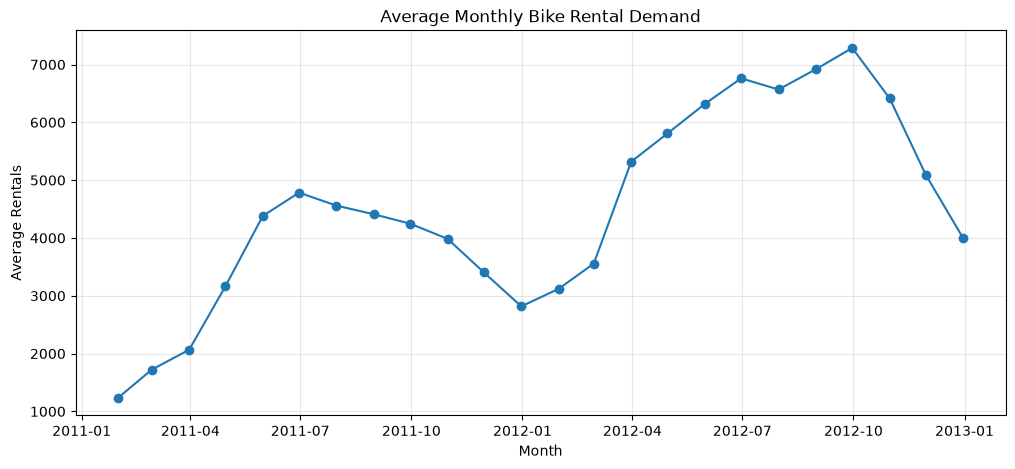

Average Daily Rentals: 4504.35
Minimum Daily Rentals: 22
Maximum Daily Rentals: 8714


In [2]:
df = df.set_index("dteday")

plt.figure(figsize=(15, 5))
plt.plot(df.index, df["cnt"])
plt.title("Daily Bike Rental Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Rentals")
plt.grid(alpha=0.3)
plt.show()

monthly_demand = df["cnt"].resample("ME").mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_demand.index, monthly_demand.values, marker="o")
plt.title("Average Monthly Bike Rental Demand")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.grid(alpha=0.3)
plt.show()

print("Average Daily Rentals:", round(df["cnt"].mean(), 2))
print("Minimum Daily Rentals:", df["cnt"].min())
print("Maximum Daily Rentals:", df["cnt"].max())

In [3]:
print("Average Daily Rentals:", round(df["cnt"].mean(), 2))
print("Minimum Daily Rentals:", df["cnt"].min())
print("Maximum Daily Rentals:", df["cnt"].max())

print("\nMonthly Average:")
print(monthly_demand.round(2).to_string())

print("\nHighest Demand Month:", monthly_demand.idxmax())
print("Lowest Demand Month:", monthly_demand.idxmin())

Average Daily Rentals: 4504.35
Minimum Daily Rentals: 22
Maximum Daily Rentals: 8714

Monthly Average:
dteday
2011-01-31    1231.90
2011-02-28    1721.96
2011-03-31    2065.97
2011-04-30    3162.33
2011-05-31    4381.32
2011-06-30    4783.73
2011-07-31    4559.39
2011-08-31    4409.39
2011-09-30    4247.27
2011-10-31    3984.23
2011-11-30    3405.57
2011-12-31    2816.87
2012-01-31    3120.77
2012-02-29    3556.45
2012-03-31    5318.55
2012-04-30    5807.47
2012-05-31    6318.23
2012-06-30    6761.00
2012-07-31    6567.97
2012-08-31    6919.45
2012-09-30    7285.77
2012-10-31    6414.23
2012-11-30    5088.80
2012-12-31    3990.74
Freq: ME

Highest Demand Month: 2012-09-30 00:00:00
Lowest Demand Month: 2011-01-31 00:00:00


### Stationarity Test (ADF Test)

In [6]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df["cnt"])

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:")

for key, value in result[4].items():
    print(f"{key}: {value}")

if result[1] <= 0.05:
    print("\nThe series is Stationary")
else:
    print("\nThe series is Non-Stationary")

ADF Statistic: -1.8774481444374307
p-value: 0.34274344033921894
Critical Values:
1%: -3.439503230053971
5%: -2.8655794463678346
10%: -2.5689210707289982

The series is Non-Stationary


C:\Users\AS\AppData\Local\Temp\ipykernel_27152\1910912098.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df["cnt"])


### Seasonal Differencing

In [7]:
df["cnt_diff"] = df["cnt"].diff(7)

result_diff = adfuller(df["cnt_diff"].dropna())

print("ADF Statistic:", result_diff[0])
print("p-value:", result_diff[1])

if result_diff[1] <= 0.05:
    print("The differenced series is Stationary")
else:
    print("The differenced series is still Non-Stationary")

ADF Statistic: -7.957324479099658
p-value: 3.012846476262947e-12
The differenced series is Stationary


C:\Users\AS\AppData\Local\Temp\ipykernel_27152\468255501.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff = adfuller(df["cnt_diff"].dropna())


In [8]:
train = df["cnt"].iloc[:-60]
test = df["cnt"].iloc[-60:]

print("Training Size:", len(train))
print("Testing Size:", len(test))

print("Training Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

Training Size: 671
Testing Size: 60
Training Period: 2011-01-01 00:00:00 to 2012-11-01 00:00:00
Testing Period: 2012-11-02 00:00:00 to 2012-12-31 00:00:00


### SARIMAX Model

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_result = model.fit(disp=False)

print(sarimax_result.summary())

c:\Users\AS\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\AS\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                               cnt   No. Observations:                  671
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 7)   Log Likelihood               -5419.562
Date:                           Fri, 06 Nov 2026   AIC                          10849.123
Time:                                   21:08:35   BIC                          10871.546
Sample:                               01-01-2011   HQIC                         10857.817
                                    - 11-01-2012                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9814      0.010    101.390      0.000       0.962       1.000
ma.L1         -0.7571      0.024    -31.772

### Forecasting + Confidence Intervals

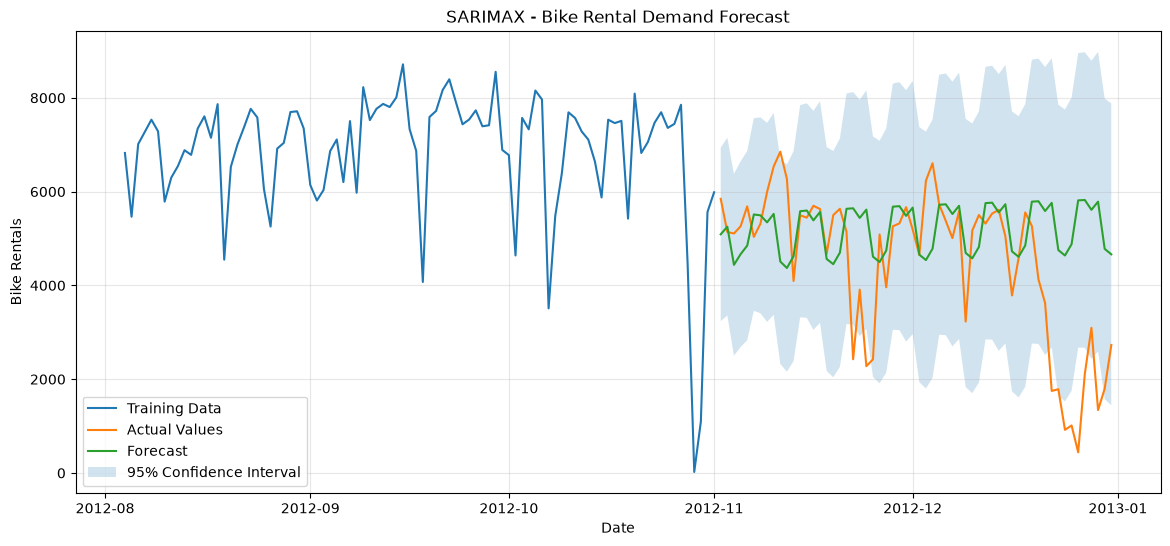

Forecast Completed!
Forecast Shape: (60,)


In [11]:
forecast_result = sarimax_result.get_forecast(steps=len(test))

forecast = forecast_result.predicted_mean
confidence_intervals = forecast_result.conf_int()

forecast.index = test.index
confidence_intervals.index = test.index

plt.figure(figsize=(14, 6))

plt.plot(train.index[-90:], train.iloc[-90:], label="Training Data")
plt.plot(test.index, test, label="Actual Values")
plt.plot(forecast.index, forecast, label="Forecast")

plt.fill_between(
    forecast.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.title("SARIMAX - Bike Rental Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Bike Rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Forecast Completed!")
print("Forecast Shape:", forecast.shape)

### Model Evaluation

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = np.mean(np.abs((test - forecast) / test)) * 100

print("Model Evaluation Results:")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

Model Evaluation Results:
MAE: 1272.19
RMSE: 1822.18
MAPE: 70.56 %


### Improve SARIMAX

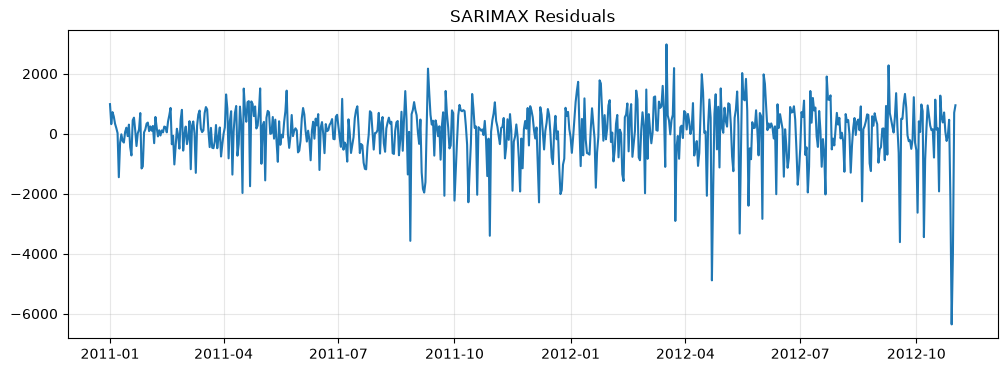

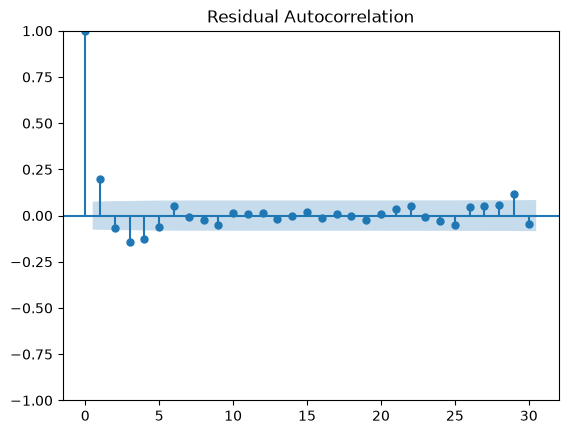

      lb_stat     lb_pvalue
7   58.207841  3.437294e-10
14  60.716056  8.782716e-08
21  62.421998  5.454004e-06


In [13]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

residuals = sarimax_result.resid.dropna()

plt.figure(figsize=(12, 4))
plt.plot(residuals)
plt.title("SARIMAX Residuals")
plt.grid(alpha=0.3)
plt.show()

plot_acf(residuals, lags=30)
plt.title("Residual Autocorrelation")
plt.show()

print(acorr_ljungbox(residuals, lags=[7, 14, 21], return_df=True))

In [14]:
model_2 = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 7),
    trend="t",
    enforce_stationarity=False,
    enforce_invertibility=False
)

result_2 = model_2.fit(disp=False)

forecast_2 = result_2.get_forecast(steps=len(test)).predicted_mean
forecast_2.index = test.index

mae_2 = mean_absolute_error(test, forecast_2)
rmse_2 = np.sqrt(mean_squared_error(test, forecast_2))
mape_2 = np.mean(np.abs((test - forecast_2) / test)) * 100

print("Original Model:")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2))

print("\nImproved Model:")
print("MAE:", round(mae_2, 2))
print("RMSE:", round(rmse_2, 2))
print("MAPE:", round(mape_2, 2))

c:\Users\AS\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\AS\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Original Model:
MAE: 1272.19
RMSE: 1822.18
MAPE: 70.56

Improved Model:
MAE: 1563.35
RMSE: 2179.66
MAPE: 85.15


c:\Users\AS\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [15]:
# Seasonal Naive Baseline: use demand from 7 days earlier
naive_forecast = test.shift(7)
naive_forecast.iloc[:7] = train.iloc[-7:].values

# Additional metrics
wape = np.sum(np.abs(test - forecast)) / np.sum(test) * 100

smape = np.mean(
    2 * np.abs(test - forecast) /
    (np.abs(test) + np.abs(forecast))
) * 100

naive_mae = mean_absolute_error(test, naive_forecast)
naive_rmse = np.sqrt(mean_squared_error(test, naive_forecast))

print("SARIMAX WAPE:", round(wape, 2), "%")
print("SARIMAX sMAPE:", round(smape, 2), "%")

print("\nSeasonal Naive Baseline:")
print("MAE:", round(naive_mae, 2))
print("RMSE:", round(naive_rmse, 2))

SARIMAX WAPE: 28.23 %
SARIMAX sMAPE: 31.83 %

Seasonal Naive Baseline:
MAE: 1488.6
RMSE: 1977.32


### SHAP Interpretability

In [17]:
import shap
from sklearn.ensemble import RandomForestRegressor

features = [
    "season", "mnth", "weekday", "workingday",
    "weathersit", "temp", "atemp", "hum",
    "windspeed", "casual", "registered"
]

X = df[features].copy()
y = df["cnt"].copy()

X_train = X.iloc[:-60]
X_test = X.iloc[-60:]

y_train = y.iloc[:-60]
y_test = y.iloc[-60:]

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=8
)

rf_model.fit(X_train, y_train)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

print("SHAP Model Training Completed!")
print("Features:", len(features))
print("SHAP Values Shape:", shap_values.values.shape)

SHAP Model Training Completed!
Features: 11
SHAP Values Shape: (60, 11)


### Feature Importance

In [18]:
shap_importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

shap_importance["Importance_Percentage"] = (
    shap_importance["Mean_Absolute_SHAP"] /
    shap_importance["Mean_Absolute_SHAP"].sum()
) * 100

display(shap_importance.round(2))

,Feature,Mean_Absolute_SHAP,Importance_Percentage
10,registered,1580.05,76.82
9,casual,442.48,21.51
5,temp,8.53,0.41
6,atemp,6.70,0.33
3,workingday,6.12,0.30
1,mnth,3.03,0.15
8,windspeed,2.86,0.14
2,weekday,2.49,0.12
0,season,1.77,0.09
7,hum,1.70,0.08


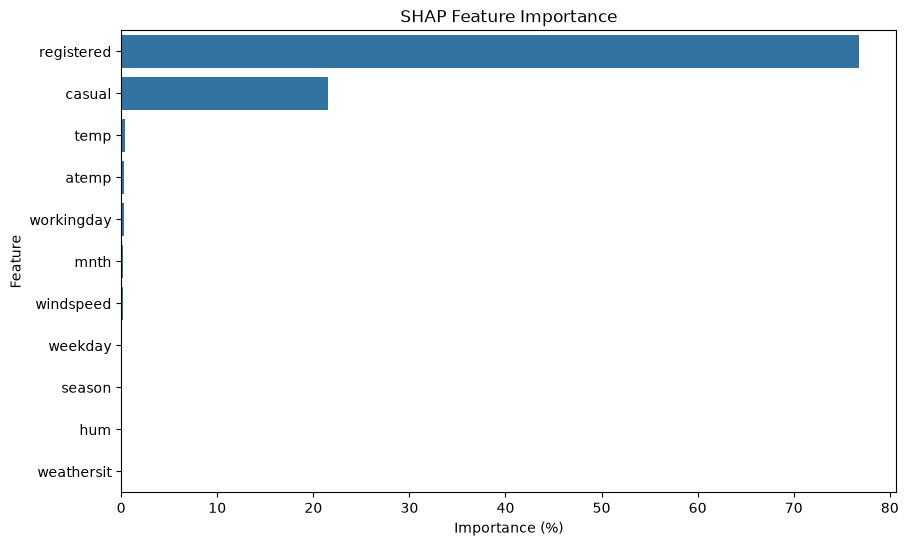

In [19]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=shap_importance,
    x="Importance_Percentage",
    y="Feature"
)

plt.title("SHAP Feature Importance")
plt.xlabel("Importance (%)")
plt.ylabel("Feature")
plt.show()